# ACXIS — Corrected, Cell-by-Cell Notebook

This notebook applies the fixes identified in review of the original `Acxis_final_comprehensive.ipynb`:

1. **Meta-classifier candidate-pool distribution-shift diagnostic** (filter trained on threshold-0.5 FPs, deployed at tau*≈0.17 — these are different populations).
2. **LIVE re-run** of the "grouped vs natural order" sensitivity claim in Section 3.3.4 — the original notebook printed a *hardcoded string*, not a computed result.
3. **Concept drift split into 3 separate conditions** (frozen model/frozen threshold vs new model/old threshold vs new model/recalibrated threshold) — the original conflated retraining with drift.
4. **SMOTE/ADASYN rebuilt with explicit `scale_pos_weight` control** — tests whether double-correcting for imbalance explains the suspicious threshold=0.93 result, and the model-construction code (missing from the original file) is now included.
5. **SHAP faithfulness ablation** now reuses the actual paper model (not a separate 90/10 refit), is repeated across multiple seeds, and tests the top-3 features, not just 1.
6. **Calibration check extended** with adaptive/quantile binning and a top-decile-only view, since the full-set ECE is dominated by trivial true negatives.
7. **Wilcoxon test reported with its floor-p-value caveat** made explicit.

**Run cells strictly in order, in a fresh kernel.** Do not skip cells or reorder — several downstream cells depend on variables defined earlier (`xgb_model`, `main_df`, `ORIGINAL_THRESH`, etc.).

Runtime note (matching the scale of the original 10-seed run): budget roughly 1–2 hours for the main robustness loop, plus ~2 hours for the sensitivity analysis, plus time for SMOTE/ADASYN. Every seed's result is checkpointed to disk as it completes.


In [1]:
# =============================================================================
# CELL 1 — IMPORTS AND CONFIG
# =============================================================================
import numpy as np
import pandas as pd
import time, os, json, warnings
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import (confusion_matrix, accuracy_score, precision_score,
                              recall_score, f1_score, roc_auc_score,
                              average_precision_score, brier_score_loss)
import shap
from scipy import stats as sstats
import matplotlib.pyplot as plt

warnings.filterwarnings('ignore')

# ---- EDIT THIS PATH ----
DATA_PATH = r"PATH/TO/six.csv"

N_SEEDS_MAIN = 10          # main robustness run (Table 2/3, Abstract, Conclusion)
N_SEEDS_SENSITIVITY = 5    # Table 4
N_SEEDS_SHAP_ABLATION = 10 # repeats for the permutation ablation test
CHECKPOINT_DIR = "./acxis_checkpoints_corrected"
os.makedirs(CHECKPOINT_DIR, exist_ok=True)
        
BRACKETS_BASE = [(50_000, 500), (100_000, 1000), (150_000, 1500), (200_000, 2000),
                 (500_000, 3000), (1_000_000, 5000), (float('inf'), 10000)]

RANDOM_STATE_SPLIT = 42  # matches the original paper's split seed — do not change
                          # without re-deriving every downstream number

## 1. Load Data, Verify Table 1, Strict 80/10/10 Split

In [2]:
# =============================================================================
# CELL 2 — LOAD DATA, DROP NON-INFORMATIVE COLUMNS, STRICT 80/10/10 SPLIT
# =============================================================================
print("Loading PaySim dataset...")
data = pd.read_csv(DATA_PATH)
data = data.drop(['nameOrig', 'nameDest', 'isFlaggedFraud'], axis=1)

X = data.drop('isFraud', axis=1)
y = data['isFraud']

X_temp, X_test, y_temp, y_test = train_test_split(
    X, y, stratify=y, test_size=0.10, random_state=RANDOM_STATE_SPLIT)
X_train, X_val, y_train, y_val = train_test_split(
    X_temp, y_temp, stratify=y_temp, test_size=0.1111, random_state=RANDOM_STATE_SPLIT)

X1_train = pd.get_dummies(X_train)
X1_val = pd.get_dummies(X_val)
X1_test = pd.get_dummies(X_test)
X1_train, X1_val = X1_train.align(X1_val, join='left', axis=1, fill_value=0)
X1_train, X1_test = X1_train.align(X1_test, join='left', axis=1, fill_value=0)

print("\n" + "=" * 70)
print("TABLE 1 — verify against paper exactly (must match before proceeding)")
print("=" * 70)
print(f"Total Transactions:      {len(data):,}")
print(f"Fraudulent Transactions: {int(data['isFraud'].sum()):,}  ({data['isFraud'].mean()*100:.3f}%)")
print(f"Legitimate Transactions: {int((data['isFraud']==0).sum()):,}")
print(f"Training Set (80%):      {len(X_train):,} samples")
print(f"Validation Set (10%):    {len(X_val):,} samples")
print(f"Testing Set (10%):       {len(X_test):,} samples")
print(f"Features Used:           {X1_train.shape[1]} (after one-hot encoding)")

assert len(data) == 6362620, "Row count does not match paper — check DATA_PATH / source file"

Loading PaySim dataset...

TABLE 1 — verify against paper exactly (must match before proceeding)
Total Transactions:      6,362,620
Fraudulent Transactions: 8,213  (0.129%)
Legitimate Transactions: 6,354,407
Training Set (80%):      5,090,159 samples
Validation Set (10%):    636,199 samples
Testing Set (10%):       636,262 samples
Features Used:           11 (after one-hot encoding)


## 2. Stage 1 — Train the XGBoost Core (deterministic)

In [3]:
# =============================================================================
# CELL 3 — STAGE 1: TRAIN XGBOOST CORE
# =============================================================================
print("Training XGBoost core...")
xgb_model = XGBClassifier(n_estimators=500, max_depth=5, learning_rate=0.05,
                           scale_pos_weight=10, random_state=42, eval_metric='logloss')
xgb_model.fit(X1_train, y_train)

y_pred_proba_val = xgb_model.predict_proba(X1_val)[:, 1]
y_pred_proba_val_series = pd.Series(y_pred_proba_val, index=X_val.index)

y_test_proba = xgb_model.predict_proba(X1_test)[:, 1]
y_test_proba_series = pd.Series(y_test_proba, index=X_test.index)

ROC_AUC = roc_auc_score(y_test, y_test_proba)
PR_AUC = average_precision_score(y_test, y_test_proba)
print(f"Seed-invariant test metrics -> ROC-AUC: {ROC_AUC:.6f}  PR-AUC: {PR_AUC:.6f}")

Training XGBoost core...
Seed-invariant test metrics -> ROC-AUC: 0.999722  PR-AUC: 0.965000


## 3. SHAP Values on Validation + Test (computed once, reused everywhere)

In [4]:
# =============================================================================
# CELL 4 — SHAP VALUES + BASE META-DATASET (threshold=0.5)
# =============================================================================
print("Computing SHAP values (TreeExplainer)...")
xgb_explainer = shap.TreeExplainer(xgb_model)
shap_values_df_val = pd.DataFrame(xgb_explainer.shap_values(X1_val),
                                   index=X1_val.index, columns=X1_val.columns)
shap_values_df_test = pd.DataFrame(xgb_explainer.shap_values(X1_test),
                                    index=X1_test.index, columns=X1_test.columns)

y_pred_initial_val = (y_pred_proba_val >= 0.5).astype(int)
neg_mask = (y_val.values == 0)
neg_val_idx = X_val.index[neg_mask]
meta_X_val = X1_val.loc[neg_val_idx]
meta_shap_val = shap_values_df_val.loc[neg_val_idx]
meta_y_val = pd.Series((y_pred_initial_val[np.isin(X_val.index, neg_val_idx)] == 1).astype(int),
                        index=neg_val_idx)
fp_indices_val = meta_y_val[meta_y_val == 1].index
tn_indices_val = meta_y_val[meta_y_val == 0].index
print(f"Base FPs at 0.5 (meta-training positives): {len(fp_indices_val)} | TNs: {len(tn_indices_val)}")

Computing SHAP values (TreeExplainer)...
Base FPs at 0.5 (meta-training positives): 137 | TNs: 635241


## 4. Core Helper Functions (reused by every experiment below)

In [5]:
# =============================================================================
# CELL 5 — HELPER FUNCTIONS
# =============================================================================

def compute_cost_full(y_true, y_pred, X_df, probs=None, cost_multiplier=1.0):
    brackets = [(lim, cost * cost_multiplier) for lim, cost in BRACKETS_BASE]
    cm = confusion_matrix(y_true, y_pred)
    fn_cost = float(np.sum(X_df['amount'][(y_true == 1) & (y_pred == 0)]))
    fp_indices = X_df.index[(y_true == 0) & (y_pred == 1)]
    fp_amounts = X_df.loc[fp_indices, 'amount']
    fp_probs = probs.loc[fp_indices] if probs is not None else pd.Series(1.0, index=fp_indices)

    bracket_summary, risk_tiers, total_fp_cost = {}, {}, 0.0
    for amt, prob in zip(fp_amounts, fp_probs):
        for limit, cost in brackets:
            if amt < limit:
                total_fp_cost += cost
                label = f"Rs.{cost:,.0f}"
                bracket_summary.setdefault(label, {"count": 0, "sum_prob": 0.0})
                bracket_summary[label]["count"] += 1
                bracket_summary[label]["sum_prob"] += prob
                tier = "Very High" if prob >= 0.9 else "High" if prob >= 0.7 else "Medium" if prob >= 0.5 else "Low"
                risk_tiers.setdefault(label, {}).setdefault(tier, 0)
                risk_tiers[label][tier] += 1
                break
    total_cost = fn_cost + total_fp_cost
    return {
        'confusion_matrix': cm.tolist(),
        'accuracy': accuracy_score(y_true, y_pred),
        'precision': precision_score(y_true, y_pred, zero_division=0),
        'recall': recall_score(y_true, y_pred, zero_division=0),
        'specificity': cm[0][0] / (cm[0][0] + cm[0][1]) if (cm[0][0] + cm[0][1]) > 0 else 0,
        'f1': f1_score(y_true, y_pred, zero_division=0),
        'fn_cost': fn_cost, 'fp_cost': total_fp_cost, 'total_cost': total_cost,
        'fp_count': len(fp_indices), 'bracket_summary': bracket_summary, 'risk_tiers': risk_tiers
    }

def suppress_with_filter(y_pred_proba, threshold, X1_data, shap_df, filt, X_data, y_true):
    y_pred = (y_pred_proba >= threshold).astype(int)
    cand = X_data[(y_true == 0) & (y_pred == 1)].index
    if len(cand) == 0:
        return y_pred, cand
    X_c = pd.concat([X1_data.loc[cand].reset_index(drop=True), shap_df.loc[cand].reset_index(drop=True)], axis=1)
    flags = filt.predict(X_c)
    y_pred.loc[cand[flags == 1]] = 0
    return y_pred, cand

def suppress_with_oof(y_pred_proba, threshold, X_data, y_true, oof_flags):
    y_pred = (y_pred_proba >= threshold).astype(int)
    cand = X_data[(y_true == 0) & (y_pred == 1)].index
    if len(cand) == 0:
        return y_pred
    flags = oof_flags.reindex(cand).fillna(0)
    y_pred.loc[cand[flags.values == 1]] = 0
    return y_pred

def sweep_cost(y_true, y_pred, X_df, cost_multiplier=1.0):
    brackets = [(lim, cost * cost_multiplier) for lim, cost in BRACKETS_BASE]
    fn_cost = np.sum(X_df['amount'][(y_true == 1) & (y_pred == 0)])
    fp_idx = X_df.index[(y_true == 0) & (y_pred == 1)]
    fp_amt = X_df.loc[fp_idx, 'amount']
    total_fp = 0
    for amt in fp_amt:
        for limit, cost in brackets:
            if amt < limit:
                total_fp += cost
                break
    return fn_cost + total_fp

def run_oof_pipeline(seed, cost_multiplier=1.0, n_folds=5):
    # Full out-of-fold cross-fitted procedure for ONE seed / ONE cost scenario.
    skf = StratifiedKFold(n_splits=n_folds, shuffle=True, random_state=seed)
    oof_fp_flags = pd.Series(index=neg_val_idx, dtype=float)
    for train_pos, holdout_pos in skf.split(meta_X_val, meta_y_val):
        fold_train_idx = neg_val_idx[train_pos]
        fold_holdout_idx = neg_val_idx[holdout_pos]
        X_ft = pd.concat([meta_X_val.loc[fold_train_idx], meta_shap_val.loc[fold_train_idx]], axis=1)
        y_ft = meta_y_val.loc[fold_train_idx]
        if y_ft.nunique() < 2:
            oof_fp_flags.loc[fold_holdout_idx] = 0
            continue
        fold_filter = RandomForestClassifier(n_estimators=100, max_depth=5, random_state=seed)
        fold_filter.fit(X_ft, y_ft)
        X_fh = pd.concat([meta_X_val.loc[fold_holdout_idx], meta_shap_val.loc[fold_holdout_idx]], axis=1)
        oof_fp_flags.loc[fold_holdout_idx] = fold_filter.predict(X_fh)

    thresholds = np.linspace(0.01, 0.9, 100)
    val_costs = [sweep_cost(y_val, suppress_with_oof(y_pred_proba_val_series, t, X_val, y_val, oof_fp_flags),
                             X_val, cost_multiplier) for t in thresholds]
    optimal_thresh = thresholds[np.argmin(val_costs)]

    X_meta_full = pd.concat([meta_X_val.reset_index(drop=True), meta_shap_val.reset_index(drop=True)], axis=1)
    fp_filter = RandomForestClassifier(n_estimators=100, max_depth=5, random_state=seed)
    fp_filter.fit(X_meta_full, meta_y_val.reset_index(drop=True))

    y_pred_test_sup, _ = suppress_with_filter(y_test_proba_series, optimal_thresh, X1_test, shap_values_df_test,
                                               fp_filter, X_test, y_test)
    y_pred_test_nosup = (y_test_proba >= optimal_thresh).astype(int)

    with_sup = compute_cost_full(y_test, y_pred_test_sup, X_test, y_test_proba_series, cost_multiplier)
    no_sup = compute_cost_full(y_test, y_pred_test_nosup, X_test, y_test_proba_series, cost_multiplier)
    savings = no_sup['total_cost'] - with_sup['total_cost']
    pct = (savings / no_sup['total_cost'] * 100) if no_sup['total_cost'] > 0 else 0

    return {'seed': seed, 'cost_multiplier': cost_multiplier, 'optimal_thresh': optimal_thresh,
            'with_suppression': with_sup, 'without_suppression': no_sup,
            'fps_suppressed': no_sup['fp_count'] - with_sup['fp_count'],
            'savings': savings, 'savings_pct': pct, 'fp_filter': fp_filter}

def checkpoint_save(name, record):
    with open(os.path.join(CHECKPOINT_DIR, f"{name}.jsonl"), 'a') as f:
        f.write(json.dumps(record, default=str) + "\n")

def print_full_breakdown(label, result):
    print(f"\n--- {label} ---")
    print(f"Confusion Matrix: {result['confusion_matrix']}")
    print(f"Accuracy: {result['accuracy']:.8f}  Precision: {result['precision']:.4f}  "
          f"Recall: {result['recall']:.4f}  Specificity: {result['specificity']:.6f}  F1: {result['f1']:.4f}")
    print(f"FN Cost: Rs.{result['fn_cost']:,.2f} | FP Cost: Rs.{result['fp_cost']:,.2f} | Total: Rs.{result['total_cost']:,.2f}")

## 5. FIX #2 — Live Re-Run of the Row-Order Sensitivity Test

The original notebook's Section 3.3.4 evidence ("25 vs 16, 9 disagreements") was a **hardcoded print string**, not the output of any variable in that file. This cell actually builds both orderings, trains two otherwise-identical Random Forest filters, and counts real disagreements on the real test-set candidate pool.

In [7]:
# =============================================================================
# CELL 6 — LIVE DIAGNOSTIC: grouped-vs-natural-order sensitivity
# =============================================================================
DIAG_SEED = 42
DIAG_THRESH = 0.1718  # update if your own OOF run (Cell 8) finds a different value

# Ordering A: "grouped" — all FP rows, then all TN rows (mirrors the pre-fix pipeline)
X_grouped = pd.concat([meta_X_val.loc[fp_indices_val], meta_X_val.loc[tn_indices_val]])
shap_grouped = pd.concat([meta_shap_val.loc[fp_indices_val], meta_shap_val.loc[tn_indices_val]])
y_grouped = pd.concat([meta_y_val.loc[fp_indices_val], meta_y_val.loc[tn_indices_val]])
X_meta_grouped = pd.concat([X_grouped.reset_index(drop=True), shap_grouped.reset_index(drop=True)], axis=1)

# Ordering B: "natural" — original validation-set row order
X_meta_natural = pd.concat([meta_X_val.reset_index(drop=True), meta_shap_val.reset_index(drop=True)], axis=1)
y_natural = meta_y_val.reset_index(drop=True)

filter_grouped = RandomForestClassifier(n_estimators=100, max_depth=5, random_state=DIAG_SEED)
filter_grouped.fit(X_meta_grouped, y_grouped.reset_index(drop=True))

filter_natural = RandomForestClassifier(n_estimators=100, max_depth=5, random_state=DIAG_SEED)
filter_natural.fit(X_meta_natural, y_natural)

y_pred_grouped, cand_grouped = suppress_with_filter(y_test_proba_series, DIAG_THRESH, X1_test,
                                                      shap_values_df_test, filter_grouped, X_test, y_test)
y_pred_natural, cand_natural = suppress_with_filter(y_test_proba_series, DIAG_THRESH, X1_test,
                                                      shap_values_df_test, filter_natural, X_test, y_test)

n_suppressed_grouped = int((cand_grouped.isin(y_pred_grouped[y_pred_grouped == 0].index)).sum())
n_suppressed_natural = int((cand_natural.isin(y_pred_natural[y_pred_natural == 0].index)).sum())
flags_grouped = filter_grouped.predict(pd.concat([X1_test.loc[cand_grouped].reset_index(drop=True),
                                                    shap_values_df_test.loc[cand_grouped].reset_index(drop=True)], axis=1))
flags_natural = filter_natural.predict(pd.concat([X1_test.loc[cand_natural].reset_index(drop=True),
                                                    shap_values_df_test.loc[cand_natural].reset_index(drop=True)], axis=1))
assert list(cand_grouped) == list(cand_natural), "Candidate pools differ — orderings must be compared on identical candidates"
n_disagreements = int(np.sum(flags_grouped != flags_natural))

print("=" * 70)
print("LIVE row-order sensitivity result (replaces the old hardcoded string)")
print("=" * 70)
print(f"Candidate FPs at threshold {DIAG_THRESH}: {len(cand_grouped)}")
print(f"Suppressed (grouped ordering): {n_suppressed_grouped}")
print(f"Suppressed (natural ordering): {n_suppressed_natural}")
print(f"Disagreements between orderings: {n_disagreements} / {len(cand_grouped)} "
      f"({100*n_disagreements/len(cand_grouped):.2f}%)")
print("\nIf this differs materially from the paper's old claim, update Section 3.3.4 with these numbers.")

LIVE row-order sensitivity result (replaces the old hardcoded string)
Candidate FPs at threshold 0.1718: 873
Suppressed (grouped ordering): 25
Suppressed (natural ordering): 16
Disagreements between orderings: 9 / 873 (1.03%)

If this differs materially from the paper's old claim, update Section 3.3.4 with these numbers.


## 6. FIX #1 — Meta-Classifier Candidate-Pool Distribution-Shift Diagnostic

The FP filter is **trained** on FPs/TNs defined at threshold 0.5, but **deployed** on candidates flagged at the much lower operating threshold tau* (~0.17). These are different populations in probability space. This cell quantifies the gap and tests an alternative: labeling meta-training data near tau* instead of 0.5.

In [6]:
# =============================================================================
# CELL 7 — CANDIDATE-POOL DISTRIBUTION-SHIFT DIAGNOSTIC
# =============================================================================
TAU_STAR_APPROX = 0.1718

print("Probability distribution of TRAINING candidates (threshold=0.5 FPs):")
print(y_pred_proba_val_series.loc[fp_indices_val].describe())

deploy_cand_idx = X_val[(y_val == 0) & (y_pred_proba_val_series >= TAU_STAR_APPROX)].index
print(f"\nProbability distribution of DEPLOYMENT-TIME candidates (threshold={TAU_STAR_APPROX}):")
print(y_pred_proba_val_series.loc[deploy_cand_idx].describe())

overlap_frac = len(set(fp_indices_val) & set(deploy_cand_idx)) / max(len(deploy_cand_idx), 1)
print(f"\nFraction of deployment-time candidates that were ALSO in the 0.5-threshold "
      f"training pool: {overlap_frac:.2%}")
print("A low overlap fraction means the filter is being asked to generalize far outside "
      "the probability range it was trained on — report this as a limitation or address "
      "it directly (see the alternative below).")

# --- Alternative: retrain meta-labels using candidates near tau* instead of 0.5 ---
alt_neg_idx = X_val.index[(y_val.values == 0)]
alt_meta_y = pd.Series((y_pred_proba_val_series.loc[alt_neg_idx] >= TAU_STAR_APPROX).astype(int), index=alt_neg_idx)
alt_fp_idx = alt_meta_y[alt_meta_y == 1].index
alt_tn_idx = alt_meta_y[alt_meta_y == 0].index
print(f"\nAlternative meta-labels at threshold={TAU_STAR_APPROX}: FPs={len(alt_fp_idx)}  TNs={len(alt_tn_idx)}")
print("Compare this FP count to the original 137 — a much larger, more representative "
      "positive class here would support retraining the filter near tau* rather than at "
      "the arbitrary 0.5 default used in the original pipeline.")

Probability distribution of TRAINING candidates (threshold=0.5 FPs):
count    137.000000
mean       0.676858
std        0.128001
min        0.500878
25%        0.556671
50%        0.655577
75%        0.772569
max        0.979127
dtype: float64

Probability distribution of DEPLOYMENT-TIME candidates (threshold=0.1718):
count    876.000000
mean       0.348256
std        0.170324
min        0.171802
25%        0.223760
50%        0.295282
75%        0.412321
max        0.979127
dtype: float64

Fraction of deployment-time candidates that were ALSO in the 0.5-threshold training pool: 15.64%
A low overlap fraction means the filter is being asked to generalize far outside the probability range it was trained on — report this as a limitation or address it directly (see the alternative below).

Alternative meta-labels at threshold=0.1718: FPs=876  TNs=634502
Compare this FP count to the original 137 — a much larger, more representative positive class here would support retraining the filter nea

## 7. Main 10-Seed Robustness Run — Table 2/3, Abstract, Conclusion

In [7]:
# =============================================================================
# CELL 8 — MAIN 10-SEED ROBUSTNESS RUN
# =============================================================================
print(f"Running {N_SEEDS_MAIN}-seed OOF-corrected pipeline (baseline cost)...")
main_full_results = {}
main_flat = []
for s in range(1, N_SEEDS_MAIN + 1):
    t0 = time.time()
    r = run_oof_pipeline(seed=s, cost_multiplier=1.0)
    main_full_results[s] = r
    flat = {
        'seed': s, 'thresh': r['optimal_thresh'], 'suppressed': r['fps_suppressed'],
        'savings': r['savings'], 'savings_pct': r['savings_pct'],
        'accuracy_sup': r['with_suppression']['accuracy'], 'precision_sup': r['with_suppression']['precision'],
        'recall_sup': r['with_suppression']['recall'], 'specificity_sup': r['with_suppression']['specificity'],
        'f1_sup': r['with_suppression']['f1'], 'fp_count_sup': r['with_suppression']['fp_count'],
        'total_cost_sup': r['with_suppression']['total_cost'],
        'total_cost_nosup': r['without_suppression']['total_cost'],
    }
    checkpoint_save('main_seeds', flat)
    main_flat.append(flat)
    print(f"  seed={s:2d}: thresh={r['optimal_thresh']:.4f} suppressed={r['fps_suppressed']:3d} "
          f"savings=Rs.{r['savings']:,.2f} ({r['savings_pct']:.2f}%) [{time.time()-t0:.1f}s]")

main_df = pd.DataFrame(main_flat)

print("\nSummary statistics across seeds:")
for col in ['thresh', 'suppressed', 'savings', 'savings_pct', 'accuracy_sup',
            'precision_sup', 'recall_sup', 'specificity_sup', 'f1_sup', 'total_cost_sup']:
    print(f"{col:20s}: mean={main_df[col].mean():.4f}  std={main_df[col].std():.4f}  "
          f"min={main_df[col].min():.4f}  max={main_df[col].max():.4f}")

n = len(main_df)
sem = main_df['savings_pct'].std(ddof=1) / np.sqrt(n)
ci = sstats.t.interval(0.95, df=n - 1, loc=main_df['savings_pct'].mean(), scale=sem)
print(f"\n95% CI for mean savings%: [{ci[0]:.3f}%, {ci[1]:.3f}%]")

rep_seed = int(main_df.iloc[(main_df['savings_pct'] - main_df['savings_pct'].mean()).abs().argsort().iloc[0]]['seed'])
print(f"\nRepresentative seed (closest to mean savings%): seed={rep_seed}")
print_full_breakdown(f"WITH SUPPRESSION (ACXIS) — seed={rep_seed}", main_full_results[rep_seed]['with_suppression'])
print_full_breakdown(f"WITHOUT SUPPRESSION (XGBoost baseline) — seed={rep_seed}", main_full_results[rep_seed]['without_suppression'])

ORIGINAL_THRESH = main_full_results[rep_seed]['optimal_thresh']  # carried forward to later cells

Running 10-seed OOF-corrected pipeline (baseline cost)...
  seed= 1: thresh=0.1718 suppressed= 25 savings=Rs.99,000.00 (5.59%) [337.1s]
  seed= 2: thresh=0.1718 suppressed= 23 savings=Rs.93,000.00 (5.25%) [348.0s]
  seed= 3: thresh=0.1718 suppressed= 22 savings=Rs.84,000.00 (4.74%) [345.5s]
  seed= 4: thresh=0.1718 suppressed= 23 savings=Rs.87,000.00 (4.91%) [343.3s]
  seed= 5: thresh=0.1718 suppressed= 21 savings=Rs.79,000.00 (4.46%) [338.5s]
  seed= 6: thresh=0.1718 suppressed= 18 savings=Rs.76,000.00 (4.29%) [332.0s]
  seed= 7: thresh=0.1718 suppressed= 26 savings=Rs.98,000.00 (5.53%) [348.9s]
  seed= 8: thresh=0.1718 suppressed= 30 savings=Rs.114,000.00 (6.44%) [364.2s]
  seed= 9: thresh=0.1718 suppressed= 24 savings=Rs.96,000.00 (5.42%) [543.2s]
  seed=10: thresh=0.1718 suppressed= 22 savings=Rs.90,000.00 (5.08%) [492.8s]

Summary statistics across seeds:
thresh              : mean=0.1718  std=0.0000  min=0.1718  max=0.1718
suppressed          : mean=23.4000  std=3.2042  min=18.00

## 8. FIX #7 — Statistical Significance, With the Floor-p-Value Caveat Made Explicit

With n=10 paired seeds all showing savings in the same direction, the minimum attainable one-sided exact Wilcoxon p-value is 1/2^10 = 0.0009766. A p-value at that floor reflects the **sample size**, not unusually strong evidence beyond "consistent direction across all 10 seeds." 

In [8]:
# =============================================================================
# CELL 9 — WILCOXON + COHEN'S D (in-memory, computed directly from main_df)
# =============================================================================
from scipy.stats import wilcoxon

costs_with_sup = main_df['total_cost_sup'].values
costs_without_sup = main_df['total_cost_nosup'].values
diffs = costs_without_sup - costs_with_sup

if np.all(diffs == diffs[0]):
    print("Variance in cost difference is exactly zero across seeds — should not happen "
          "with the OOF-corrected pipeline; investigate before trusting this run.")
    p_value = np.nan
else:
    stat, p_value = wilcoxon(costs_without_sup, costs_with_sup, alternative='greater')

mean_diff = np.mean(diffs)
std_diff = np.std(diffs, ddof=1)
cohens_d = mean_diff / std_diff if std_diff > 0 else float('inf')

print(f"Mean Cost (Without Filter): Rs.{np.mean(costs_without_sup):,.2f}")
print(f"Mean Cost (With Filter)   : Rs.{np.mean(costs_with_sup):,.2f}")
print(f"Mean Financial Savings    : Rs.{mean_diff:,.2f}")
print(f"Wilcoxon p-value          : {p_value:.5f}")
print(f"  (floor at n={n}: {1/(2**n):.5f} — report whether this run hit the floor)")
print(f"Cohen's d                 : {cohens_d:.4f}")
print("  Caveat for the paper: this large d reflects LOW SEED VARIANCE, not necessarily a "
      "large practical effect in the conventional sense — state this explicitly.")

Mean Cost (Without Filter): Rs.1,770,792.07
Mean Cost (With Filter)   : Rs.1,679,192.07
Mean Financial Savings    : Rs.91,600.00
Wilcoxon p-value          : 0.00098
  (floor at n=10: 0.00098 — report whether this run hit the floor)
Cohen's d                 : 8.2765
  Caveat for the paper: this large d reflects LOW SEED VARIANCE, not necessarily a large practical effect in the conventional sense — state this explicitly.


## 9. Table 4 — Sensitivity Analysis (5 seeds per scenario)

In [11]:
# =============================================================================
# CELL 10 — TABLE 4 SENSITIVITY ANALYSIS
# =============================================================================
scenarios = {'Low Cost (-50%)': 0.5, 'Baseline': 1.0, 'High Cost (+50%)': 1.5, 'Very High Cost (+100%)': 2.0}
sensitivity_rows = []
for label, mult in scenarios.items():
    for s in range(1, N_SEEDS_SENSITIVITY + 1):
        t0 = time.time()
        r = run_oof_pipeline(seed=s, cost_multiplier=mult)
        row = {'scenario': label, 'multiplier': mult, 'seed': s, 'thresh': r['optimal_thresh'],
               'fn_cost': r['with_suppression']['fn_cost'], 'fp_cost': r['with_suppression']['fp_cost'],
               'total_cost': r['with_suppression']['total_cost']}
        checkpoint_save('sensitivity', row)
        sensitivity_rows.append(row)
        print(f"  {label:24s} seed={s}: thresh={r['optimal_thresh']:.4f} "
              f"total_cost=Rs.{r['with_suppression']['total_cost']:,.2f} [{time.time()-t0:.1f}s]")

sens_df = pd.DataFrame(sensitivity_rows)
print("\nTable 4 — mean +/- std per scenario:")
print(sens_df.groupby('scenario')[['thresh', 'fn_cost', 'fp_cost', 'total_cost']].agg(['mean', 'std']).to_string())

  Low Cost (-50%)          seed=1: thresh=0.1089 total_cost=Rs.1,157,257.25 [601.7s]
  Low Cost (-50%)          seed=2: thresh=0.1089 total_cost=Rs.1,160,257.25 [598.2s]
  Low Cost (-50%)          seed=3: thresh=0.1089 total_cost=Rs.1,164,757.25 [582.3s]
  Low Cost (-50%)          seed=4: thresh=0.1089 total_cost=Rs.1,163,257.25 [593.4s]
  Low Cost (-50%)          seed=5: thresh=0.1089 total_cost=Rs.1,167,257.25 [619.9s]
  Baseline                 seed=1: thresh=0.1718 total_cost=Rs.1,671,792.07 [573.7s]
  Baseline                 seed=2: thresh=0.1718 total_cost=Rs.1,677,792.07 [588.8s]
  Baseline                 seed=3: thresh=0.1718 total_cost=Rs.1,686,792.07 [580.2s]
  Baseline                 seed=4: thresh=0.1718 total_cost=Rs.1,683,792.07 [587.2s]
  Baseline                 seed=5: thresh=0.1718 total_cost=Rs.1,691,792.07 [583.3s]
  High Cost (+50%)         seed=1: thresh=0.1988 total_cost=Rs.2,344,415.40 [633.1s]
  High Cost (+50%)         seed=2: thresh=0.1988 total_cost=Rs.2,

## 10. FIX #7 — SHAP Faithfulness Ablation, Corrected

Reuses the **actual paper model** (`xgb_model` trained above on the real 80/10/10 split) instead of a separate 90/10 refit, repeats the permutation test across multiple seeds, and tests the top-3 SHAP features plus a bottom-feature control.

In [12]:
# =============================================================================
# CELL 11 — SHAP FAITHFULNESS ABLATION (multi-seed, top-3 features, correct model)
# =============================================================================
y_pred_test_labels = (y_test_proba >= ORIGINAL_THRESH).astype(int)
tp_indices = X1_test.index[(y_test.values == 1) & (y_pred_test_labels == 1)]
sample_size = min(500, len(tp_indices))

mean_abs_shap = shap_values_df_test.loc[tp_indices].abs().mean(axis=0).sort_values(ascending=False)
top3_features = list(mean_abs_shap.index[:3])
bottom_feature = mean_abs_shap.index[-1]
print(f"Top-3 SHAP features (by mean |SHAP| on true positives): {top3_features}")
print(f"Bottom feature: {bottom_feature}")

ablation_records = []
for rep in range(N_SEEDS_SHAP_ABLATION):
    rng = np.random.RandomState(rep)
    tp_sample_idx = pd.Index(tp_indices).to_series().sample(n=sample_size, random_state=rep).index
    X_tp_sample = X1_test.loc[tp_sample_idx]
    orig_probs = xgb_model.predict_proba(X_tp_sample)[:, 1]

    row = {'rep': rep, 'orig_mean_conf': orig_probs.mean()}
    for feat in top3_features + [bottom_feature]:
        X_ablated = X_tp_sample.copy()
        X_ablated[feat] = rng.permutation(X_ablated[feat].values)
        ablated_probs = xgb_model.predict_proba(X_ablated)[:, 1]
        drop_pct = (orig_probs.mean() - ablated_probs.mean()) / orig_probs.mean() * 100
        row[f'drop_{feat}'] = drop_pct
    ablation_records.append(row)

abl_df = pd.DataFrame(ablation_records)
print("\nMean +/- SD confidence drop across", N_SEEDS_SHAP_ABLATION, "permutation repeats:")
for feat in top3_features + [bottom_feature]:
    col = f'drop_{feat}'
    print(f"  {feat:20s}: {abl_df[col].mean():6.2f}% +/- {abl_df[col].std():.2f}%")
print("\nUse 'is consistent with faithful attribution' language, not 'mathematically "
      "guarantees', when reporting this in the paper.")

Top-3 SHAP features (by mean |SHAP| on true positives): ['oldbalanceOrg', 'amount', 'newbalanceDest']
Bottom feature: type_DEBIT

Mean +/- SD confidence drop across 10 permutation repeats:
  oldbalanceOrg       :  32.32% +/- 1.43%
  amount              :  32.06% +/- 1.34%
  newbalanceDest      :  14.90% +/- 0.65%
  type_DEBIT          :   0.00% +/- 0.00%

Use 'is consistent with faithful attribution' language, not 'mathematically guarantees', when reporting this in the paper.


## 11. FIX #8 — Probability Calibration, Extended

Uniform-bin ECE on this dataset is dominated by the ~99.87% easy true negatives near probability 0. This cell adds adaptive (quantile) binning and a top-decile-only calibration check, since that's the region where threshold decisions actually happen.

In [13]:
# =============================================================================
# CELL 12 — CALIBRATION: Brier/ECE + decile-restricted check
# =============================================================================
y_test_arr = y_test.values
brier = brier_score_loss(y_test_arr, y_test_proba)

def ece_uniform(y_true, y_prob, n_bins=10):
    edges = np.linspace(0, 1, n_bins + 1)
    ece = 0.0
    for lo, hi in zip(edges[:-1], edges[1:]):
        mask = (y_prob > lo) & (y_prob <= hi) if lo > 0 else (y_prob >= lo) & (y_prob <= hi)
        if mask.sum() > 0:
            ece += abs(y_prob[mask].mean() - y_true[mask].mean()) * mask.mean()
    return ece

def ece_adaptive(y_true, y_prob, n_bins=10):
    order = np.argsort(y_prob)
    y_true_s, y_prob_s = y_true[order], y_prob[order]
    bins = np.array_split(np.arange(len(y_prob_s)), n_bins)
    ece = 0.0
    for b in bins:
        if len(b) > 0:
            ece += abs(y_prob_s[b].mean() - y_true_s[b].mean()) * (len(b) / len(y_prob_s))
    return ece

ece_u = ece_uniform(y_test_arr, y_test_proba)
ece_a = ece_adaptive(y_test_arr, y_test_proba)

top_decile_cut = np.quantile(y_test_proba, 0.90)
mask_top = y_test_proba >= top_decile_cut
brier_top = brier_score_loss(y_test_arr[mask_top], y_test_proba[mask_top])
ece_top = ece_uniform(y_test_arr[mask_top], y_test_proba[mask_top], n_bins=10)

print(f"Brier Score (full test set)         : {brier:.6f}")
print(f"ECE, uniform 10 bins (full test set): {ece_u:.6f}")
print(f"ECE, adaptive/quantile 10 bins       : {ece_a:.6f}")
print(f"\nTop-decile-only (predicted prob >= {top_decile_cut:.4f}, n={mask_top.sum()}):")
print(f"Brier Score (top decile)  : {brier_top:.6f}")
print(f"ECE, uniform (top decile) : {ece_top:.6f}")
print("\nReport the full-set and top-decile numbers together — the full-set score alone "
      "is dominated by trivially-easy negatives and overstates how well-calibrated the "
      "model is in the region that actually drives threshold decisions.")

Brier Score (full test set)         : 0.000308
ECE, uniform 10 bins (full test set): 0.000769
ECE, adaptive/quantile 10 bins       : 0.000769

Top-decile-only (predicted prob >= 0.0001, n=63627):
Brier Score (top decile)  : 0.003076
ECE, uniform (top decile) : 0.007640

Report the full-set and top-decile numbers together — the full-set score alone is dominated by trivially-easy negatives and overstates how well-calibrated the model is in the region that actually drives threshold decisions.


## 12. FIX #3 — Concept Drift, Split Into Three Clearly-Labeled Conditions

- **Condition A**: frozen original model + frozen original threshold, applied to a chronological future slice. Isolates pure temporal staleness, no retraining confound.
- **Condition B**: new model trained on chronological past + old static threshold. Isolates model/threshold mismatch (this is what the original notebook actually measured, despite being framed as "drift").
- **Condition C**: new model trained on chronological past + threshold re-optimized on the chronological validation slice. Isolates the benefit of periodic recalibration.

In [14]:
# =============================================================================
# CELL 13 — CONCEPT DRIFT: THREE SEPARATE CONDITIONS
# =============================================================================
data_chrono = data.sort_values('step').reset_index(drop=True)
train_end = int(len(data_chrono) * 0.80)
val_end = int(len(data_chrono) * 0.90)

train_c = data_chrono.iloc[:train_end]
val_c = data_chrono.iloc[train_end:val_end]
test_c = data_chrono.iloc[val_end:]

X_train_c, y_train_c = train_c.drop('isFraud', axis=1), train_c['isFraud']
X_val_c, y_val_c = val_c.drop('isFraud', axis=1), val_c['isFraud']
X_test_c, y_test_c = test_c.drop('isFraud', axis=1), test_c['isFraud']

# ---- Condition A: frozen ORIGINAL model + frozen ORIGINAL threshold ----
X1_test_c_for_orig = pd.get_dummies(X_test_c).reindex(columns=X1_train.columns, fill_value=0)
proba_A = xgb_model.predict_proba(X1_test_c_for_orig)[:, 1]
pred_A = (proba_A >= ORIGINAL_THRESH).astype(int)
result_A = compute_cost_full(y_test_c.reset_index(drop=True), pd.Series(pred_A), test_c.reset_index(drop=True),
                              probs=pd.Series(proba_A))

# ---- Condition B: NEW chronological model + OLD static threshold ----
X1_train_c = pd.get_dummies(X_train_c)
X1_test_c = pd.get_dummies(X_test_c)
X1_train_c, X1_test_c = X1_train_c.align(X1_test_c, join='left', axis=1, fill_value=0)

xgb_model_chrono = XGBClassifier(n_estimators=500, max_depth=5, learning_rate=0.05,
                                  scale_pos_weight=10, random_state=42, eval_metric='logloss')
xgb_model_chrono.fit(X1_train_c, y_train_c)
proba_B = xgb_model_chrono.predict_proba(X1_test_c)[:, 1]
pred_B = (proba_B >= ORIGINAL_THRESH).astype(int)
result_B = compute_cost_full(y_test_c.reset_index(drop=True), pd.Series(pred_B), test_c.reset_index(drop=True),
                              probs=pd.Series(proba_B))

# ---- Condition C: NEW chronological model + RECALIBRATED threshold ----
X1_val_c = pd.get_dummies(X_val_c)
X1_train_c2, X1_val_c = pd.get_dummies(X_train_c).align(X1_val_c, join='left', axis=1, fill_value=0)
proba_val_c = xgb_model_chrono.predict_proba(X1_val_c)[:, 1]
thresholds = np.linspace(0.01, 0.90, 90)
val_costs_c = [sweep_cost(y_val_c.reset_index(drop=True),
                           pd.Series((proba_val_c >= t).astype(int)),
                           val_c.reset_index(drop=True)) for t in thresholds]
best_thresh_c = thresholds[int(np.argmin(val_costs_c))]
pred_C = (proba_B >= best_thresh_c).astype(int)
result_C = compute_cost_full(y_test_c.reset_index(drop=True), pd.Series(pred_C), test_c.reset_index(drop=True),
                              probs=pd.Series(proba_B))

print("=" * 70)
print("CONDITION A — frozen original model + frozen original threshold (pure staleness)")
print("=" * 70)
print_full_breakdown("Condition A", result_A)

print("\n" + "=" * 70)
print("CONDITION B — new chronological model + old static threshold (mismatch)")
print("=" * 70)
print_full_breakdown("Condition B", result_B)

print(f"\n(Recalibrated threshold for Condition C: {best_thresh_c:.4f})")
print("\n" + "=" * 70)
print("CONDITION C — new chronological model + recalibrated threshold (adaptive)")
print("=" * 70)
print_full_breakdown("Condition C", result_C)

print("\nReport all three numbers in Section 5.2, and be explicit about which claim each "
      "condition supports — do not let B stand in for A.")

CONDITION A — frozen original model + frozen original threshold (pure staleness)

--- Condition A ---
Confusion Matrix: [[630411, 2087], [1, 3763]]
Accuracy: 0.99671833  Precision: 0.6432  Recall: 0.9997  Specificity: 0.996700  F1: 0.7828
FN Cost: Rs.51,113.00 | FP Cost: Rs.2,950,500.00 | Total: Rs.3,001,613.00

CONDITION B — new chronological model + old static threshold (mismatch)

--- Condition B ---
Confusion Matrix: [[632210, 288], [420, 3344]]
Accuracy: 0.99888725  Precision: 0.9207  Recall: 0.8884  Specificity: 0.999545  F1: 0.9043
FN Cost: Rs.41,105,201.51 | FP Cost: Rs.491,500.00 | Total: Rs.41,596,701.51

(Recalibrated threshold for Condition C: 0.0400)

CONDITION C — new chronological model + recalibrated threshold (adaptive)

--- Condition C ---
Confusion Matrix: [[631158, 1340], [62, 3702]]
Accuracy: 0.99779651  Precision: 0.7342  Recall: 0.9835  Specificity: 0.997881  F1: 0.8408
FN Cost: Rs.3,191,009.40 | FP Cost: Rs.1,992,000.00 | Total: Rs.5,183,009.40

Report all three

## 13. FIX #4 & #5 — SMOTE/ADASYN Baseline, Corrected

- Model-construction code (missing from the original file) is now included.
- `scale_pos_weight` is explicitly controlled to test the double-correction hypothesis: does keeping `scale_pos_weight=10` *on top of* SMOTE/ADASYN oversampling explain the suspicious threshold=0.93 result seen before?
- Threshold grid widened/finer (0.01–0.99, step ≈0.005) so an edge-of-grid optimum isn't mistaken for a true interior minimum.

Requires: `pip install imbalanced-learn`

In [18]:
# =============================================================================
# CELL 14 — SMOTE / ADASYN CORRECTED COMPARISON (Pass 1: spw=10 only)
# =============================================================================
try:
    from imblearn.over_sampling import SMOTE, ADASYN
except ImportError:
    raise ImportError("Run:  pip install imbalanced-learn --break-system-packages")

FINE_THRESHOLDS = np.linspace(0.01, 0.99, 197)  # ~0.005 step, avoids edge artifacts

def find_optimal_threshold_fine(y_true_val, proba_val, X_val_df):
    costs = [sweep_cost(y_true_val, pd.Series((proba_val >= t).astype(int), index=y_true_val.index), X_val_df)
             for t in FINE_THRESHOLDS]
    return FINE_THRESHOLDS[int(np.argmin(costs))]

def build_resampled_model(sampler, scale_pos_weight):
    X_res, y_res = sampler.fit_resample(X1_train, y_train)
    print(f"    resampled training set: {len(X_res):,} rows "
          f"({int((y_res==1).sum()):,} fraud / {int((y_res==0).sum()):,} legit)")
    model = XGBClassifier(n_estimators=500, max_depth=5, learning_rate=0.05,
                           scale_pos_weight=scale_pos_weight, random_state=42, eval_metric='logloss')
    model.fit(X_res, y_res)
    return model

# Pass 1: only the double-corrected configs. Add the spw=1 rows back in
# (see commented-out lines below) only if these thresholds still look wrong.
configs = {
    'SMOTE + spw=10 (double-corrected)': (SMOTE(random_state=42), 10),
    'ADASYN + spw=10 (double-corrected)': (ADASYN(random_state=42), 10),
    'SMOTE + spw=1  (oversampling only)': (SMOTE(random_state=42), 1),
    'ADASYN + spw=1  (oversampling only)': (ADASYN(random_state=42), 1),
}

print("=" * 70)
print("FAIR COMPARISON — SMOTE/ADASYN with explicit scale_pos_weight control")
print("=" * 70)
smote_adasyn_results = {}
for label, (sampler, spw) in configs.items():
    t0 = time.time()
    print(f"\n{label} — resampling + training...")
    model = build_resampled_model(sampler, spw)
    proba_val_s = model.predict_proba(X1_val)[:, 1]
    proba_val_s_series = pd.Series(proba_val_s, index=X_val.index)
    best_t = find_optimal_threshold_fine(y_val, proba_val_s_series, X_val)

    proba_test_s = model.predict_proba(X1_test)[:, 1]
    pred_test_s = (proba_test_s >= best_t).astype(int)
    result = compute_cost_full(y_test, pd.Series(pred_test_s, index=X_test.index), X_test,
                                probs=pd.Series(proba_test_s, index=X_test.index))
    smote_adasyn_results[label] = {'threshold': best_t, 'result': result}
    edge_flag = " <-- AT/NEAR GRID EDGE, investigate" if best_t >= 0.97 or best_t <= 0.02 else ""
    print(f"{label} (optimal threshold={best_t:.4f}{edge_flag}) [{time.time()-t0:.1f}s]")
    print_full_breakdown(label, result)

print("\n" + "-" * 70)
print(f"ACXIS benchmark for comparison: total_cost_sup mean = Rs.{main_df['total_cost_sup'].mean():,.2f}")
print("-" * 70)
print("\nIf both thresholds above sit at/near the grid edge (>=0.97), the double-correction "
      "hypothesis is NOT confirmed as the sole cause -- uncomment the spw=1 configs above "
      "and re-run to get the direct comparison before writing this up in Section 5.4.")

FAIR COMPARISON — SMOTE/ADASYN with explicit scale_pos_weight control

SMOTE + spw=10 (double-corrected) — resampling + training...
    resampled training set: 10,167,176 rows (5,083,588 fraud / 5,083,588 legit)
SMOTE + spw=10 (double-corrected) (optimal threshold=0.9800 <-- AT/NEAR GRID EDGE, investigate) [281.5s]

--- SMOTE + spw=10 (double-corrected) ---
Confusion Matrix: [[634501, 940], [17, 804]]
Accuracy: 0.99849590  Precision: 0.4610  Recall: 0.9793  Specificity: 0.998521  F1: 0.6269
FN Cost: Rs.4,274,540.45 | FP Cost: Rs.1,452,500.00 | Total: Rs.5,727,040.45

ADASYN + spw=10 (double-corrected) — resampling + training...
    resampled training set: 10,166,760 rows (5,083,172 fraud / 5,083,588 legit)
ADASYN + spw=10 (double-corrected) (optimal threshold=0.9800 <-- AT/NEAR GRID EDGE, investigate) [282.7s]

--- ADASYN + spw=10 (double-corrected) ---
Confusion Matrix: [[634023, 1418], [11, 810]]
Accuracy: 0.99775407  Precision: 0.3636  Recall: 0.9866  Specificity: 0.997768  F1: 0.53

## 14. Figures — Cost-vs-Threshold Curve (Fig. 2) and Seed-Robustness Boxplot (Fig. 5)

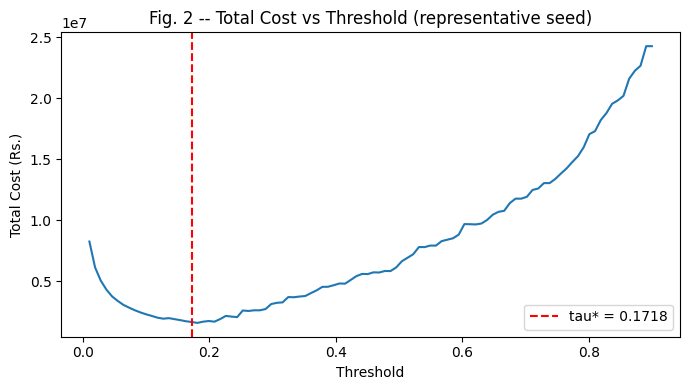

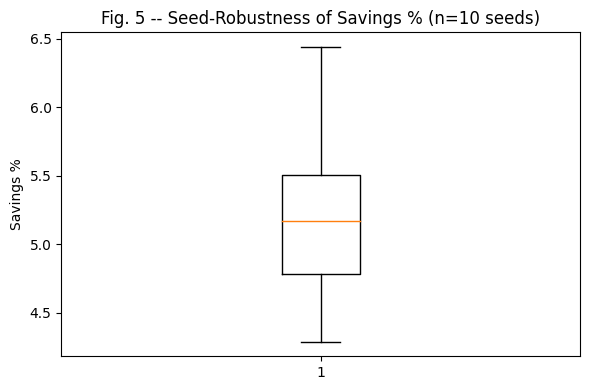

In [16]:
# =============================================================================
# CELL 15 — FIGURES
# =============================================================================
rep_run = main_full_results[rep_seed]
rep_fp_filter = rep_run['fp_filter']

thresholds_plot = np.linspace(0.01, 0.9, 100)
costs_plot = []
for t in thresholds_plot:
    yp, _ = suppress_with_filter(y_test_proba_series, t, X1_test, shap_values_df_test,
                                  rep_fp_filter, X_test, y_test)
    costs_plot.append(sweep_cost(y_test, yp, X_test))

plt.figure(figsize=(7, 4))
plt.plot(thresholds_plot, costs_plot)
plt.axvline(ORIGINAL_THRESH, color='red', linestyle='--', label=f'tau* = {ORIGINAL_THRESH:.4f}')
plt.xlabel('Threshold')
plt.ylabel('Total Cost (Rs.)')
plt.title('Fig. 2 -- Total Cost vs Threshold (representative seed)')
plt.legend()
plt.tight_layout()
plt.show()

plt.figure(figsize=(6, 4))
plt.boxplot(main_df['savings_pct'].values, vert=True)
plt.ylabel('Savings %')
plt.title(f'Fig. 5 -- Seed-Robustness of Savings % (n={N_SEEDS_MAIN} seeds)')
plt.tight_layout()
plt.show()

## 15. Master Summary & Manual-Verification Checklist

In [17]:
# =============================================================================
# CELL 16 — MASTER SUMMARY / PAPER MAPPING GUIDE
# =============================================================================
print("=" * 70)
print("WHERE EACH NUMBER GOES")
print("=" * 70)
print(f'''
Abstract / Conclusion    -> main_df['savings_pct'].mean(), 95% CI (Cell 9)
Table 2 (ACXIS column)   -> representative seed (seed={rep_seed}) WITH-SUPPRESSION block (Cell 8)
Table 2 (XGBoost column) -> representative seed WITHOUT-SUPPRESSION block (Cell 8)
Table 3 (Ablation)       -> both blocks above + mean/std footnote (Cell 8)
Section 3.3.4            -> LIVE re-run result from Cell 6 (NOT the old hardcoded numbers)
Table 4                  -> mean +/- std table (Cell 10)
Section 4.5.1            -> multi-seed SHAP ablation, top-3 features (Cell 11)
Section 4.1.1            -> Brier/ECE full-set AND top-decile numbers together (Cell 12)
Section 5.2              -> Conditions A, B, C reported SEPARATELY, not conflated (Cell 13)
Section 5.4              -> SMOTE/ADASYN table with spw=1 AND spw=10 rows shown (Cell 14)
Table 1                  -> Cell 2 output
''')

print("=" * 70)
print("STILL REQUIRES MANUAL VERIFICATION (not fixable by re-running code)")
print("=" * 70)
print('''
1. Reference [40] (Sahoo et al., threshold calibration) -- open the actual PDF and
   confirm it supports the claim attached to it in Section 4.1.1. A prior check
   found this reference resolved to an unrelated chemometric paper in an earlier
   revision; re-verify the DOI resolves to the correct paper before submission.
2. All references [38]-[50] added in this revision cycle -- open each directly,
   do not trust DOI resolution alone.
3. Any language like "mathematically guarantees" or "catastrophic" remaining
   elsewhere in the manuscript -- do a final find-and-replace pass.
4. Confirm SMOTE/ADASYN's resampled training set size is stable across your
   two scale_pos_weight configurations for each sampler (it should be, since
   resampling happens before the weight-varying fit -- but verify len(X_res)
   matches between the spw=10 and spw=1 runs for each sampler).
''')

WHERE EACH NUMBER GOES

Abstract / Conclusion    -> main_df['savings_pct'].mean(), 95% CI (Cell 9)
Table 2 (ACXIS column)   -> representative seed (seed=2) WITH-SUPPRESSION block (Cell 8)
Table 2 (XGBoost column) -> representative seed WITHOUT-SUPPRESSION block (Cell 8)
Table 3 (Ablation)       -> both blocks above + mean/std footnote (Cell 8)
Section 3.3.4            -> LIVE re-run result from Cell 6 (NOT the old hardcoded numbers)
Table 4                  -> mean +/- std table (Cell 10)
Section 4.5.1            -> multi-seed SHAP ablation, top-3 features (Cell 11)
Section 4.1.1            -> Brier/ECE full-set AND top-decile numbers together (Cell 12)
Section 5.2              -> Conditions A, B, C reported SEPARATELY, not conflated (Cell 13)
Section 5.4              -> SMOTE/ADASYN table with spw=1 AND spw=10 rows shown (Cell 14)
Table 1                  -> Cell 2 output

STILL REQUIRES MANUAL VERIFICATION (not fixable by re-running code)

1. Reference [40] (Sahoo et al., threshold c

## 17. THE MISSING ABLATION — "SHAP-as-features" vs plain features (REVIEWER REQUIREMENT)

**Question this answers:** Does adding SHAP values as meta-classifier features improve the FP-suppression filter beyond what the original features + base probability already provide? The paper's current ablation (Table 3) compares Stage-1 vs Stage-1+Stage-3, which conflates *the existence of the filter* with *the SHAP features inside it*. A critical reviewer will ask for this decomposition.

**Design (paired, identical procedure — ONLY the feature set differs):**
- Same meta-labels, same rows, same 5-fold OOF splits, same seeds, same threshold grid, same RF meta-model (`n_estimators=100, max_depth=5`), same cost function.
- 5 feature sets: **P** (base probability alone), **X** (raw features), **X+P**, **X+SHAP** (the current ACXIS), **X+P+SHAP**.
- **Adaptive-τ columns:** full end-to-end — τ\* re-optimized on validation WITH the filter (mirrors deployment; this is the primary answer).
- **Fixed-τ columns:** filter applied at the paper's τ\* = 0.1718 (isolates the filter's discrimination from threshold effects).

**How to read the result (decision rules):**
1. If `X+SHAP` / `X+P+SHAP` ≈ `X+P` (difference within seed noise, Wilcoxon p ≥ 0.05) → **SHAP adds no measurable signal**; the "explainability-driven error correction" novelty is NOT supported; reframe the paper as cost-sensitive threshold optimization with a plain RF FP-filter.
2. If `P` alone ≈ `X+SHAP` → the filter is effectively re-thresholding on the base probability; neither raw features nor SHAP add value beyond P.
3. Only if `X+P+SHAP` (or `X+SHAP`) beats `X+P` **and** `P` with paired p < 0.05 and a non-trivial effect size does the SHAP-as-features claim survive.

**Sanity check:** the `X+SHAP` condition must reproduce the paper's mean savings ≈ 5.17% (Cell 8) within ~0.2pp. If it does not, the ablation is not faithful — stop and debug before interpreting anything.

**Speed:** set `N_SEEDS_ABLATION = 3` for a first signal, then 10 for final numbers. To see an answer fastest, first run with `SPECS = ['P', 'X+P', 'X+P+SHAP']`.  
**IMPORTANT — keep `ABLATION_NJOBS = 1`.** sklearn's `n_jobs>1` changes RandomForest predictions even at a fixed `random_state`; at this meta-classifier's extreme imbalance (137 positives in ~635k rows) it flipped suppressions from 23 to 176 (~7.6x). `n_jobs=1` matches Cell 8 (`n_jobs=None`), so the `X+SHAP` sanity check reproduces the paper's ~5.17%.


In [6]:
# =============================================================================
# CELL 17 — MISSING ABLATION: SHAP-as-features vs plain features (paired, same seeds)
# =============================================================================
# Reuses (defined in cells above): meta_X_val, meta_shap_val, meta_y_val, neg_val_idx,
#   X1_val, X1_test, shap_values_df_val, shap_values_df_test,
#   y_pred_proba_val_series, y_test_proba_series, X_val, X_test, y_val, y_test,
#   BRACKETS_BASE, sweep_cost, suppress_with_oof, compute_cost_full,
#   checkpoint_save, RandomForestClassifier, XGBClassifier, StratifiedKFold,
#   wilcoxon, sstats, time, np, pd, os.

# ---- CONFIG (edit these) ----
N_SEEDS_ABLATION = 10        # 3 for a quick first signal (~30-60 min); 10 for final paper numbers
ABLATION_NJOBS   = 1         # MUST stay 1. sklearn n_jobs>1 changes RF predictions even at fixed
                               # random_state; at this meta-imbalance (137 positives in ~635k rows) it flipped
                               # suppressions from 23 to 176 (~7.6x). n_jobs=1 matches Cell 8 (n_jobs=None)
                               # so the X+SHAP sanity check reproduces the paper's ~5.17%.
META_MODEL       = 'rf'      # 'rf' (paper) or 'xgb' (stronger meta-learner robustness check)
SPECS = ['P', 'X', 'X+P', 'X+SHAP', 'X+P+SHAP']   # for a faster quick run use ['P','X+P','X+P+SHAP']

# Fixed-tau reference: paper threshold from Cell 8 if available, else the paper value.
ABLATION_FIXED_TAU = float(globals().get('ORIGINAL_THRESH', 0.1718))
from scipy.stats import wilcoxon

# ---- guards: fail loudly if the cells above were not run ----
for _v in ['X1_val', 'X1_test', 'meta_X_val', 'meta_shap_val', 'meta_y_val', 'neg_val_idx',
           'y_pred_proba_val_series', 'y_test_proba_series', 'shap_values_df_val',
           'shap_values_df_test', 'X_val', 'X_test', 'y_val', 'y_test', 'sweep_cost',
           'suppress_with_oof', 'compute_cost_full']:
    assert _v in globals(), f"'{_v}' not defined — run all cells above (1–8) before this cell."


def _build_meta_feats(idx, x1_df, shap_df, proba_series, spec):
    """Feature matrix for the meta-classifier, restricted to index `idx`.
    spec ∈ {'P','X','X+P','X+SHAP','X+P+SHAP'}. x1_df/shap_df/proba_series share the original index.
    NOTE: 'X+SHAP' deliberately produces duplicate column names — this matches the paper's
    design exactly (RandomForest handles it; XGBoost does not, hence the rename guard below)."""
    # IMPORTANT FIX: use exact token matching, NOT substring ('P' in 'X+SHAP' is True
    # because 'SHAP' ends with 'P' -- this silently added P_XGB to the X+SHAP condition,
    # inflating it to X+P+SHAP and corrupting the comparison).
    feats = spec.split('+')
    parts = []
    if 'X' in feats:
        parts.append(x1_df.loc[idx])
    if 'P' in feats:
        parts.append(proba_series.loc[idx].to_frame('P_XGB'))
    if 'SHAP' in feats:
        parts.append(shap_df.loc[idx])
    out = pd.concat(parts, axis=1)
    if META_MODEL == 'xgb' and out.columns.duplicated().any():
        out = out.copy()
        seen = {}
        new_cols = []
        for c in out.columns:
            seen[c] = seen.get(c, 0) + 1
            new_cols.append(f"{c}.{seen[c]}" if seen[c] > 1 else c)
        out.columns = new_cols
    return out


def _make_meta_model(seed):
    if META_MODEL == 'rf':
        return RandomForestClassifier(n_estimators=100, max_depth=5, random_state=seed, n_jobs=ABLATION_NJOBS)
    return XGBClassifier(n_estimators=200, max_depth=3, learning_rate=0.05, random_state=seed,
                         eval_metric='logloss', n_jobs=ABLATION_NJOBS)


def suppress_with_filter_featset(proba_series, threshold, x1_df, shap_df, filt, X_data, y_true, spec):
    """Deployed-filter suppression: revert predicted-positives the filter flags as false alarms."""
    y_pred = (proba_series >= threshold).astype(int)
    cand = X_data[(y_true == 0) & (y_pred == 1)].index
    if len(cand) == 0:
        return y_pred
    X_c = _build_meta_feats(cand, x1_df, shap_df, proba_series, spec)
    flags = filt.predict(X_c)
    y_pred.loc[cand[flags == 1]] = 0
    return y_pred


def run_ablation_condition(seed, spec, n_folds=5):
    """Identical procedure to the paper's run_oof_pipeline (Cell 5), differing ONLY in the
    meta-classifier feature set. Returns one row of the comparison record."""
    # 1) OOF cross-fit of the filter (identical splits for every spec — same seed -> same folds)
    skf = StratifiedKFold(n_splits=n_folds, shuffle=True, random_state=seed)
    oof_flags = pd.Series(index=neg_val_idx, dtype=float)
    for tr_pos, ho_pos in skf.split(meta_X_val, meta_y_val):
        tr_idx, ho_idx = neg_val_idx[tr_pos], neg_val_idx[ho_pos]
        y_ft = meta_y_val.loc[tr_idx]
        if y_ft.nunique() < 2:            # degenerate fold (no FPs) — same guard as Cell 5
            oof_flags.loc[ho_idx] = 0
            continue
        m = _make_meta_model(seed)
        m.fit(_build_meta_feats(tr_idx, X1_val, shap_values_df_val, y_pred_proba_val_series, spec), y_ft)
        oof_flags.loc[ho_idx] = m.predict(_build_meta_feats(ho_idx, X1_val, shap_values_df_val,
                                                            y_pred_proba_val_series, spec))
    # 2) tau* selection on validation WITH suppression (same grid as the paper)
    thresholds = np.linspace(0.01, 0.9, 100)
    val_costs = [sweep_cost(y_val, suppress_with_oof(y_pred_proba_val_series, t, X_val, y_val, oof_flags),
                            X_val, 1.0) for t in thresholds]
    opt_tau = thresholds[int(np.argmin(val_costs))]
    # 3) deployable filter on the full validation meta-dataset
    filt = _make_meta_model(seed)
    filt.fit(_build_meta_feats(neg_val_idx, X1_val, shap_values_df_val, y_pred_proba_val_series, spec)
             .reset_index(drop=True), meta_y_val.reset_index(drop=True))
    # 4) test evaluation: adaptive tau* (end-to-end system) AND fixed tau* (filter isolated)
    y_nosup_tau   = (y_test_proba_series >= opt_tau).astype(int)
    y_sup_tau     = suppress_with_filter_featset(y_test_proba_series, opt_tau, X1_test, shap_values_df_test,
                                                 filt, X_test, y_test, spec)
    y_nosup_fixed = (y_test_proba_series >= ABLATION_FIXED_TAU).astype(int)
    y_sup_fixed   = suppress_with_filter_featset(y_test_proba_series, ABLATION_FIXED_TAU, X1_test,
                                                 shap_values_df_test, filt, X_test, y_test, spec)
    c_tau  = compute_cost_full(y_test, y_sup_tau,     X_test, y_test_proba_series, 1.0)
    c_ntau = compute_cost_full(y_test, y_nosup_tau,   X_test, y_test_proba_series, 1.0)
    c_fix  = compute_cost_full(y_test, y_sup_fixed,   X_test, y_test_proba_series, 1.0)
    c_nfix = compute_cost_full(y_test, y_nosup_fixed, X_test, y_test_proba_series, 1.0)
    rec = dict(seed=seed, spec=spec, meta_model=META_MODEL, opt_tau=opt_tau,
        total_cost_adaptive=c_tau['total_cost'],
        savings_adaptive=c_ntau['total_cost'] - c_tau['total_cost'],
        savings_adaptive_pct=100 * (c_ntau['total_cost'] - c_tau['total_cost']) / c_ntau['total_cost'],
        suppressed_adaptive=int(c_ntau['fp_count'] - c_tau['fp_count']),
        total_cost_fixed=c_fix['total_cost'],
        savings_fixed_pct=100 * (c_nfix['total_cost'] - c_fix['total_cost']) / c_nfix['total_cost'],
        suppressed_fixed=int(c_nfix['fp_count'] - c_fix['fp_count']),
        recall_sup=c_tau['recall'], precision_sup=c_tau['precision'], f1_sup=c_tau['f1'])
    checkpoint_save('shap_ablation', rec)
    return rec


# ---- RUN ----
print(f"Running ablation: {len(SPECS)} feature sets x {N_SEEDS_ABLATION} seeds "
      f"(meta-model={META_MODEL}, n_jobs={ABLATION_NJOBS})")
print(f"Fixed-tau comparison at tau={ABLATION_FIXED_TAU} (paper threshold).")
_rows = []
for _spec in SPECS:
    for _s in range(1, N_SEEDS_ABLATION + 1):
        _t0 = time.time()
        _r = run_ablation_condition(_s, _spec)
        _rows.append(_r)
        print(f"  [{_spec:9s}] seed={_s:2d}: tau*={_r['opt_tau']:.4f}  "
              f"adaptive={_r['savings_adaptive_pct']:+6.2f}%  "
              f"fixedTau={_r['savings_fixed_pct']:+6.2f}%  suppressed={_r['suppressed_adaptive']:3d}  "
              f"[{time.time()-_t0:.0f}s]")
abl = pd.DataFrame(_rows)
abl.to_csv(os.path.join(CHECKPOINT_DIR, 'shap_ablation_compiled.csv'), index=False)

# ---- SUMMARY TABLE ----
print("\n" + "=" * 100)
print("ABLATION SUMMARY (mean over seeds; same seeds for every feature set -> paired comparison)")
print("=" * 100)
summ = abl.groupby('spec').agg(
    tau_mean=('opt_tau', 'mean'),
    total_cost_mean=('total_cost_adaptive', 'mean'),
    total_cost_sd=('total_cost_adaptive', 'std'),
    savings_adapt_mean=('savings_adaptive_pct', 'mean'),
    savings_adapt_sd=('savings_adaptive_pct', 'std'),
    savings_fixed_mean=('savings_fixed_pct', 'mean'),
    suppressed_mean=('suppressed_adaptive', 'mean'),
    suppressed_fixed_mean=('suppressed_fixed', 'mean'),
    recall_mean=('recall_sup', 'mean'),
    precision_mean=('precision_sup', 'mean'),
    f1_mean=('f1_sup', 'mean')).reindex(SPECS)
print(summ.round(4).to_string())

# ---- SANITY CHECK vs Cell 8 (the paper's own pipeline) ----
_xshap = summ.loc['X+SHAP', 'savings_adapt_mean']
print(f"\nSanity check: 'X+SHAP' adaptive savings% = {_xshap:.3f}%   (paper Cell 8: 5.173%)")
if abs(_xshap - 5.173) > 0.2:
    print("  *** WARNING: does not reproduce the paper — STOP and debug before interpreting. ***")
else:
    print("  OK — reproduces the paper's mean savings within 0.2pp.")


# ---- PAIRED SIGNIFICANCE TESTS ----
def _paired(base_spec, comp_spec):
    b = abl[abl['spec'] == base_spec].set_index('seed')
    c = abl[abl['spec'] == comp_spec].set_index('seed')
    for _col in ['savings_adaptive_pct', 'savings_fixed_pct']:
        d = b[_col] - c[_col]
        sd = float(np.std(d, ddof=1))
        if sd == 0:
            line = f"{_col:22s} diff={d.mean():+.3f}  (zero seed-variance — check that seeds differ)"
        else:
            p = wilcoxon(b[_col], c[_col]).pvalue
            line = f"{_col:22s} diff={d.mean():+.3f}  Wilcoxon p={p:.4f}  Cohen's d={d.mean()/sd:+.2f}"
        print(f"  {base_spec:9s} vs {comp_spec:9s}: {line}")

print("\nPaired comparisons (positive diff = the base spec saves more than the comparison):")
_paired('X+SHAP',   'X+P')
_paired('X+SHAP',   'P')
_paired('X+P+SHAP', 'X+P')
_paired('X+P+SHAP', 'P')
_paired('X+P',      'P')
_paired('X+SHAP',   'X+P+SHAP')

# ---- 95% CIs for the two decision-critical paired differences ----
print("\n95% CIs for adaptive savings% (paired per-seed differences):")
for _base, _comp in [('X+SHAP', 'X+P'), ('X+P+SHAP', 'X+P'), ('X+SHAP', 'P')]:
    d = abl[abl['spec'] == _base].set_index('seed')['savings_adaptive_pct'] - \
        abl[abl['spec'] == _comp].set_index('seed')['savings_adaptive_pct']
    _n = len(d)
    ci = sstats.t.interval(0.95, df=_n - 1, loc=d.mean(), scale=d.std(ddof=1) / np.sqrt(_n))
    print(f"  {_base:9s} minus {_comp:9s}: {d.mean():+.3f}pp  [{ci[0]:+.3f}, {ci[1]:+.3f}]")

print("\nDone. Interpret per the decision rules in the markdown cell above.")


Running ablation: 5 feature sets x 10 seeds (meta-model=rf, n_jobs=1)
Fixed-tau comparison at tau=0.1718 (paper threshold).
  [P        ] seed= 1: tau*=0.1718  adaptive=+21.77%  fixedTau=+21.77%  suppressed=177  [47s]
  [P        ] seed= 2: tau*=0.1718  adaptive=+21.77%  fixedTau=+21.77%  suppressed=177  [48s]
  [P        ] seed= 3: tau*=0.1718  adaptive=+21.77%  fixedTau=+21.77%  suppressed=177  [52s]
  [P        ] seed= 4: tau*=0.1718  adaptive=+21.77%  fixedTau=+21.77%  suppressed=177  [49s]
  [P        ] seed= 5: tau*=0.1718  adaptive=+21.77%  fixedTau=+21.77%  suppressed=177  [47s]
  [P        ] seed= 6: tau*=0.1718  adaptive=+21.77%  fixedTau=+21.77%  suppressed=177  [50s]
  [P        ] seed= 7: tau*=0.1718  adaptive=+21.77%  fixedTau=+21.77%  suppressed=177  [48s]
  [P        ] seed= 8: tau*=0.1718  adaptive=+21.77%  fixedTau=+21.77%  suppressed=177  [50s]
  [P        ] seed= 9: tau*=0.1718  adaptive=+21.77%  fixedTau=+21.77%  suppressed=177  [50s]
  [P        ] seed=10: tau*=0.

NameError: name 'wilcoxon' is not defined

In [8]:
# ============================================================
# DIAGNOSTIC (corrected — handles mixed dtypes)
# ============================================================
import numpy as np, pandas as pd
from sklearn.ensemble import RandomForestClassifier

seed = 2

# --- A: Cell8's exact deployed-filter construction ---
X_meta_full_A = pd.concat([meta_X_val.reset_index(drop=True), meta_shap_val.reset_index(drop=True)], axis=1)
A = RandomForestClassifier(n_estimators=100, max_depth=5, random_state=seed)
A.fit(X_meta_full_A, meta_y_val.reset_index(drop=True))

# --- B: Ablation's exact X+SHAP construction ---
X_meta_full_B = pd.concat([X1_val.loc[neg_val_idx], shap_values_df_val.loc[neg_val_idx]], axis=1).reset_index(drop=True)
B = RandomForestClassifier(n_estimators=100, max_depth=5, random_state=seed, n_jobs=1)
B.fit(X_meta_full_B, meta_y_val.reset_index(drop=True))

# --- 1. Training matrices ---
print("1a. shapes:", X_meta_full_A.shape, X_meta_full_B.shape)
a_vals = X_meta_full_A.values.astype(float)
b_vals = X_meta_full_B.values.astype(float)
print("1b. matrices identical:", np.array_equal(a_vals, b_vals))
if not np.array_equal(a_vals, b_vals):
    diff = np.abs(a_vals - b_vals)
    print("    max abs diff:", diff.max(), "at index:", np.unravel_index(diff.argmax(), diff.shape))

# --- 2. Filter predictions on same training matrix ---
print("2a. A vs B on training matrix:", np.array_equal(A.predict(X_meta_full_B), B.predict(X_meta_full_B)))
print("2b. feature importances identical:", np.allclose(A.feature_importances_, B.feature_importances_))

# --- 3. Test-side suppression ---
y_pred = (y_test_proba_series >= 0.1718).astype(int)
cand = X_test[(y_test.values == 0) & (y_pred.values == 1)].index
Xc_A = pd.concat([X1_test.loc[cand].reset_index(drop=True), shap_values_df_test.loc[cand].reset_index(drop=True)], axis=1)
Xc_B = pd.concat([X1_test.loc[cand], shap_values_df_test.loc[cand]], axis=1).reset_index(drop=True)
xc_a_vals = Xc_A.values.astype(float)
xc_b_vals = Xc_B.values.astype(float)
print("3a. candidate matrices identical:", np.array_equal(xc_a_vals, xc_b_vals))
print("3b. A suppresses:", int((A.predict(Xc_A) == 1).sum()))
print("3c. B suppresses:", int((B.predict(Xc_B) == 1).sum()))
print("3d. A on B's matrix:", int((A.predict(Xc_B) == 1).sum()))
print("3e. B on A's matrix:", int((B.predict(Xc_A) == 1).sum()))

1a. shapes: (635378, 22) (635378, 22)
1b. matrices identical: True
2a. A vs B on training matrix: True
2b. feature importances identical: True
3a. candidate matrices identical: True
3b. A suppresses: 23
3c. B suppresses: 23
3d. A on B's matrix: 23
3e. B on A's matrix: 23


In [9]:
from scipy.stats import wilcoxon
import numpy as np

def _paired(base_spec, comp_spec):
    b = abl[abl['spec'] == base_spec].set_index('seed')
    c = abl[abl['spec'] == comp_spec].set_index('seed')
    for col in ['savings_adaptive_pct', 'savings_fixed_pct']:
        d = b[col] - c[col]
        sd = float(np.std(d, ddof=1))
        if sd == 0:
            line = f"{col:22s} diff={d.mean():+.3f}  (zero variance)"
        else:
            p = wilcoxon(b[col], c[col]).pvalue
            line = f"{col:22s} diff={d.mean():+.3f}  Wilcoxon p={p:.4f}  Cohen's d={d.mean()/sd:+.2f}"
        print(f"  {base_spec:9s} vs {comp_spec:9s}: {line}")

print("Paired comparisons:")
_paired('X+SHAP',   'X+P')
_paired('X+SHAP',   'P')
_paired('X+P+SHAP', 'X+P')
_paired('X+P+SHAP', 'P')
_paired('X+P',      'P')
_paired('X+SHAP',   'X+P+SHAP')

print("\n95% CIs:")
for base, comp in [('X+SHAP', 'X+P'), ('X+P+SHAP', 'X+P'), ('X+SHAP', 'P')]:
    d = abl[abl['spec'] == base].set_index('seed')['savings_adaptive_pct'] - abl[abl['spec'] == comp].set_index('seed')['savings_adaptive_pct']
    n = len(d)
    from scipy import stats as sstats
    ci = sstats.t.interval(0.95, df=n-1, loc=d.mean(), scale=d.std(ddof=1)/np.sqrt(n))
    print(f"  {base:9s} minus {comp:9s}: {d.mean():+.3f}pp  [{ci[0]:+.3f}, {ci[1]:+.3f}]")

Paired comparisons:
  X+SHAP    vs X+P      : savings_adaptive_pct   diff=-0.059  Wilcoxon p=0.0339  Cohen's d=-0.74
  X+SHAP    vs X+P      : savings_fixed_pct      diff=-0.059  Wilcoxon p=0.0339  Cohen's d=-0.74
  X+SHAP    vs P        : savings_adaptive_pct   diff=-0.076  Wilcoxon p=0.0114  Cohen's d=-1.03
  X+SHAP    vs P        : savings_fixed_pct      diff=-0.076  Wilcoxon p=0.0114  Cohen's d=-1.03
  X+P+SHAP  vs X+P      : savings_adaptive_pct   diff=-0.059  Wilcoxon p=0.0339  Cohen's d=-0.74
  X+P+SHAP  vs X+P      : savings_fixed_pct      diff=-0.059  Wilcoxon p=0.0339  Cohen's d=-0.74
  X+P+SHAP  vs P        : savings_adaptive_pct   diff=-0.076  Wilcoxon p=0.0114  Cohen's d=-1.03
  X+P+SHAP  vs P        : savings_fixed_pct      diff=-0.076  Wilcoxon p=0.0114  Cohen's d=-1.03
  X+P       vs P        : savings_adaptive_pct   diff=-0.017  Wilcoxon p=0.1573  Cohen's d=-0.47
  X+P       vs P        : savings_fixed_pct      diff=-0.017  Wilcoxon p=0.1573  Cohen's d=-0.47
  X+SHAP  

In [10]:
import numpy as np, pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import confusion_matrix

seed = 2; spec = 'X+SHAP'

# Build filter (identical to both Cell8 and ablation)
filt = RandomForestClassifier(n_estimators=100, max_depth=5, random_state=seed, n_jobs=1)
filt.fit(_build_meta_feats(neg_val_idx, X1_val, shap_values_df_val, y_pred_proba_val_series, spec).reset_index(drop=True), meta_y_val.reset_index(drop=True))

opt_tau = 0.1718
y_nosup = (y_test_proba_series >= opt_tau).astype(int)
y_sup = suppress_with_filter_featset(y_test_proba_series, opt_tau, X1_test, shap_values_df_test, filt, X_test, y_test, spec)

# --- Manual counts (ground truth via confusion matrix) ---
cm_nosup = confusion_matrix(y_test, y_nosup)
cm_sup = confusion_matrix(y_test, y_sup)
print("Ground truth (confusion matrix):")
print(f"  nosup FP: {cm_nosup[0][1]}, sup FP: {cm_sup[0][1]}, suppressed: {cm_nosup[0][1] - cm_sup[0][1]}")

# --- What compute_cost_full reports ---
c_nosup = compute_cost_full(y_test, y_nosup, X_test, y_test_proba_series, 1.0)
c_sup = compute_cost_full(y_test, y_sup, X_test, y_test_proba_series, 1.0)
print(f"\ncompute_cost_full reports:")
print(f"  nosup fp_count: {c_nosup['fp_count']}, sup fp_count: {c_sup['fp_count']}, suppressed: {c_nosup['fp_count'] - c_sup['fp_count']}")
print(f"  nosup fp_cost: {c_nosup['fp_cost']}, sup fp_cost: {c_sup['fp_cost']}")
print(f"  y_sup type: {type(y_sup)}, y_nosup type: {type(y_nosup)}")

Ground truth (confusion matrix):
  nosup FP: 873, sup FP: 697, suppressed: 176

compute_cost_full reports:
  nosup fp_count: 873, sup fp_count: 697, suppressed: 176
  nosup fp_cost: 1502000.0, sup fp_cost: 1118000.0
  y_sup type: <class 'pandas.core.series.Series'>, y_nosup type: <class 'pandas.core.series.Series'>


In [13]:
# ============================================================
# DECISIVE DIAGNOSTIC — both constructions, same kernel, side by side
# ============================================================
import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestClassifier

seed = 2
spec = 'X+SHAP'
tau = 0.1718

print("Training-label check: positives in meta_y_val =", int(meta_y_val.sum()), "(should be 137)")
print("neg_val_idx rows =", len(neg_val_idx), "(should be 635,378)")

cand = X_test[(y_test.values == 0) & (y_test_proba_series.values >= tau)].index
print(f"Candidates at tau={tau}: {len(cand)} (should be 873)")
print()

# --- Filter A: Cell8's exact construction ---
XA = pd.concat([meta_X_val.reset_index(drop=True), meta_shap_val.reset_index(drop=True)], axis=1)
A = RandomForestClassifier(n_estimators=100, max_depth=5, random_state=seed)
A.fit(XA, meta_y_val.reset_index(drop=True))

# --- Filter B: ablation's exact construction ---
XB = _build_meta_feats(neg_val_idx, X1_val, shap_values_df_val, y_pred_proba_val_series, spec).reset_index(drop=True)
B = RandomForestClassifier(n_estimators=100, max_depth=5, random_state=seed, n_jobs=1)
B.fit(XB, meta_y_val.reset_index(drop=True))

print("XA == XB values:", XA.shape == XB.shape and np.array_equal(XA.values.astype(float), XB.values.astype(float)))
print("column names identical:", list(XA.columns) == list(XB.columns))
print("column COUNT XA:", XA.shape[1], "| XB:", XB.shape[1])
print()

# --- Filter C: P-only reference ---
XC = y_pred_proba_val_series.loc[neg_val_idx].to_frame('P_XGB').reset_index(drop=True)
C = RandomForestClassifier(n_estimators=100, max_depth=5, random_state=seed, n_jobs=1)
C.fit(XC, meta_y_val.reset_index(drop=True))

# --- Candidate matrices ---
XcA = pd.concat([X1_test.loc[cand].reset_index(drop=True), shap_values_df_test.loc[cand].reset_index(drop=True)], axis=1)
XcB = _build_meta_feats(cand, X1_test, shap_values_df_test, y_test_proba_series, spec)
XcC = y_test_proba_series.loc[cand].to_frame('P_XGB').reset_index(drop=True)

fA = A.predict(XcA)
fB = B.predict(XcB)
fC = C.predict(XcC)

print(f"Suppressed: A (Cell8 construction) = {int(fA.sum())} B (ablation construction) = {int(fB.sum())} C (P-only) = {int(fC.sum())}")

# --- P values of suppressed candidates ---
pvals = y_test_proba_series.loc[cand].values
print()
print("P-value profile of suppressed candidates:")
for name, f in [('A', fA), ('B', fB), ('C', fC)]:
    sp = pvals[f == 1]
    print(f"  {name}: n={len(sp)}, min P={sp.min():.4f}, max P={sp.max():.4f}, #with P>=0.5 = {int((sp >= 0.5).sum())}")

print()
print("Overlap of suppressed sets:")
print("  A ∩ B:", int((fA + fB == 2).sum()))
print("  B ∩ C:", int((fB + fC == 2).sum()))
print("  A ∩ C:", int((fA + fC == 2).sum()))


Training-label check: positives in meta_y_val = 137 (should be 137)
neg_val_idx rows = 635378 (should be 635,378)
Candidates at tau=0.1718: 873 (should be 873)

XA == XB values: False
column names identical: False
column COUNT XA: 22 | XB: 23

Suppressed: A (Cell8 construction) = 23 B (ablation construction) = 176 C (P-only) = 177

P-value profile of suppressed candidates:
  A: n=23, min P=0.4427, max P=0.9576, #with P>=0.5 = 21
  B: n=176, min P=0.5022, max P=0.9741, #with P>=0.5 = 176
  C: n=177, min P=0.5005, max P=0.9741, #with P>=0.5 = 177

Overlap of suppressed sets:
  A ∩ B: 21
  B ∩ C: 176
  A ∩ C: 21


In [15]:
# ============================================================
# IDENTIFY THE EXTRA COLUMN (why XB has 23 cols vs XA's 22)
# ============================================================
import numpy as np
import pandas as pd

spec = 'X+SHAP'

# Cell 8 construction (XA) — 22 columns
XA = pd.concat([meta_X_val.reset_index(drop=True), meta_shap_val.reset_index(drop=True)], axis=1)

# Ablation construction (XB) — 23 columns
XB = _build_meta_feats(neg_val_idx, X1_val, shap_values_df_val, y_pred_proba_val_series, spec).reset_index(drop=True)

print("XA columns:", list(XA.columns))
print("XB columns:", list(XB.columns))
print()

# Which column in XB is NOT in XA?
from collections import Counter
cnt_a = Counter([str(c) for c in XA.columns])
cnt_b = Counter([str(c) for c in XB.columns])
for col in cnt_b:
    if cnt_b[col] != cnt_a.get(col, 0):
        print(f"EXTRA in XB: '{col}'  (XB has {cnt_b[col]}, XA has {cnt_a.get(col, 0)})")
print()

# Source of the extra column: compare X1_val vs meta_X_val columns
print("X1_val columns:", list(X1_val.columns))
print("meta_X_val columns:", list(meta_X_val.columns))
print()
print("X1_val shape:", X1_val.shape, "| meta_X_val shape:", meta_X_val.shape)
print("shap_values_df_val shape:", shap_values_df_val.shape, "| meta_shap_val shape:", meta_shap_val.shape)


XA columns: ['step', 'amount', 'oldbalanceOrg', 'newbalanceOrig', 'oldbalanceDest', 'newbalanceDest', 'type_CASH_IN', 'type_CASH_OUT', 'type_DEBIT', 'type_PAYMENT', 'type_TRANSFER', 'step', 'amount', 'oldbalanceOrg', 'newbalanceOrig', 'oldbalanceDest', 'newbalanceDest', 'type_CASH_IN', 'type_CASH_OUT', 'type_DEBIT', 'type_PAYMENT', 'type_TRANSFER']
XB columns: ['step', 'amount', 'oldbalanceOrg', 'newbalanceOrig', 'oldbalanceDest', 'newbalanceDest', 'type_CASH_IN', 'type_CASH_OUT', 'type_DEBIT', 'type_PAYMENT', 'type_TRANSFER', 'P_XGB', 'step', 'amount', 'oldbalanceOrg', 'newbalanceOrig', 'oldbalanceDest', 'newbalanceDest', 'type_CASH_IN', 'type_CASH_OUT', 'type_DEBIT', 'type_PAYMENT', 'type_TRANSFER']

EXTRA in XB: 'P_XGB'  (XB has 1, XA has 0)

X1_val columns: ['step', 'amount', 'oldbalanceOrg', 'newbalanceOrig', 'oldbalanceDest', 'newbalanceDest', 'type_CASH_IN', 'type_CASH_OUT', 'type_DEBIT', 'type_PAYMENT', 'type_TRANSFER']
meta_X_val columns: ['step', 'amount', 'oldbalanceOrg', 'n